In [40]:
# Сравнение линейной модели и дерева на данных make_moons

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams['figure.figsize'] = (8, 6)

Train: 350 объектов, Test: 150 объектов
Классов: 2, доля класса 1: 0.50


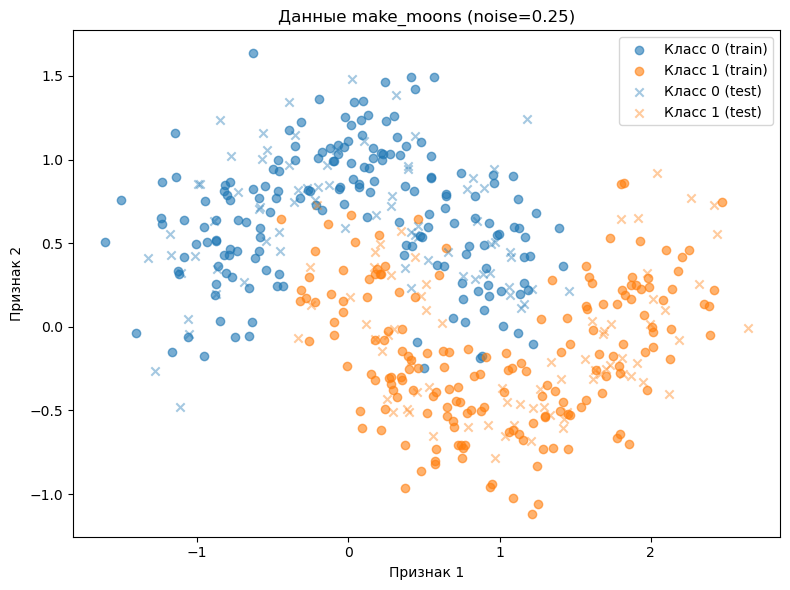

In [42]:
# два полумесяца
X, y = make_moons(n_samples=500, noise=0.25, random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)

print(f"Train: {X_train.shape[0]} объектов, Test: {X_test.shape[0]} объектов")
print(f"Классов: {len(np.unique(y))}, доля класса 1: {y.mean():.2f}")

plt.figure()
plt.scatter(X_train[y_train == 0][:, 0], X_train[y_train == 0][:, 1],
            c='tab:blue', label='Класс 0 (train)', alpha=0.6)
plt.scatter(X_train[y_train == 1][:, 0], X_train[y_train == 1][:, 1],
            c='tab:orange', label='Класс 1 (train)', alpha=0.6)
plt.scatter(X_test[y_test == 0][:, 0], X_test[y_test == 0][:, 1],
            c='tab:blue', marker='x', label='Класс 0 (test)', alpha=0.4)
plt.scatter(X_test[y_test == 1][:, 0], X_test[y_test == 1][:, 1],
            c='tab:orange', marker='x', label='Класс 1 (test)', alpha=0.4)
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.title('Данные make_moons (noise=0.25)')
plt.legend()
plt.tight_layout()
plt.show()

In [44]:
def plot_decision_boundary(model, X, y, title, ax):
    """Граница решения модели на плоскости."""
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.scatter(X[y == 0][:, 0], X[y == 0][:, 1], c='tab:blue',
               edgecolor='k', s=30, label='Класс 0')
    ax.scatter(X[y == 1][:, 0], X[y == 1][:, 1], c='tab:orange',
               edgecolor='k', s=30, label='Класс 1')
    ax.set_xlabel('Признак 1')
    ax.set_ylabel('Признак 2')
    ax.set_title(title)

LogisticRegression — train acc: 0.854, test acc: 0.840


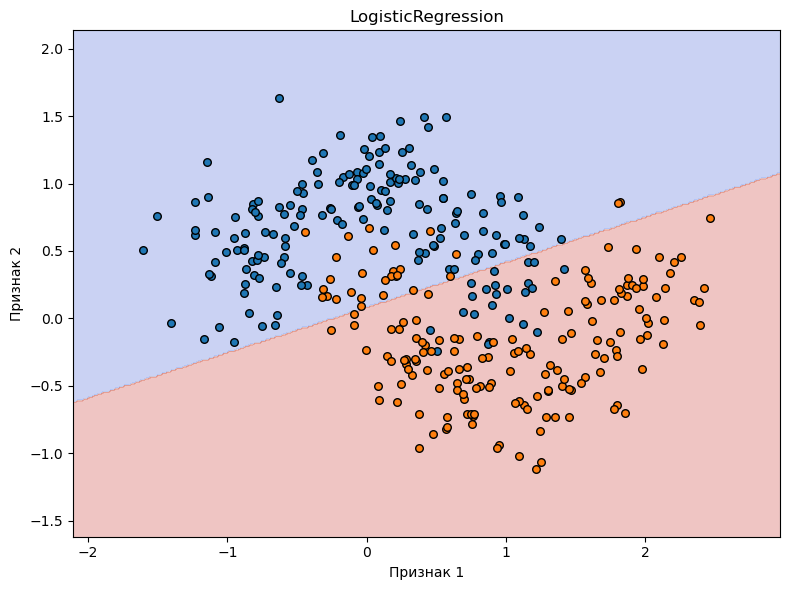

In [46]:
# линейная модель: логистическая регрессия
log_reg = LogisticRegression(random_state=RANDOM_STATE)
log_reg.fit(X_train, y_train)

y_train_pred_lr = log_reg.predict(X_train)
y_test_pred_lr = log_reg.predict(X_test)

acc_train_lr = accuracy_score(y_train, y_train_pred_lr)
acc_test_lr = accuracy_score(y_test, y_test_pred_lr)

print(f"LogisticRegression — train acc: {acc_train_lr:.3f}, test acc: {acc_test_lr:.3f}")

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
plot_decision_boundary(log_reg, X_train, y_train, 'LogisticRegression', ax)
plt.tight_layout()
plt.show()

In [48]:
# дерево решений с разными глубинами
depths = [1, 2, 3, 5, 10, None]
tree_results = []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    tree.fit(X_train, y_train)
    train_acc = accuracy_score(y_train, tree.predict(X_train))
    test_acc = accuracy_score(y_test, tree.predict(X_test))
    tree_results.append((d, train_acc, test_acc))
    print(f"max_depth={str(d):>4} — train acc: {train_acc:.3f}, test acc: {test_acc:.3f}")

max_depth=   1 — train acc: 0.843, test acc: 0.807
max_depth=   2 — train acc: 0.911, test acc: 0.893
max_depth=   3 — train acc: 0.911, test acc: 0.893
max_depth=   5 — train acc: 0.974, test acc: 0.947
max_depth=  10 — train acc: 1.000, test acc: 0.947
max_depth=None — train acc: 1.000, test acc: 0.947


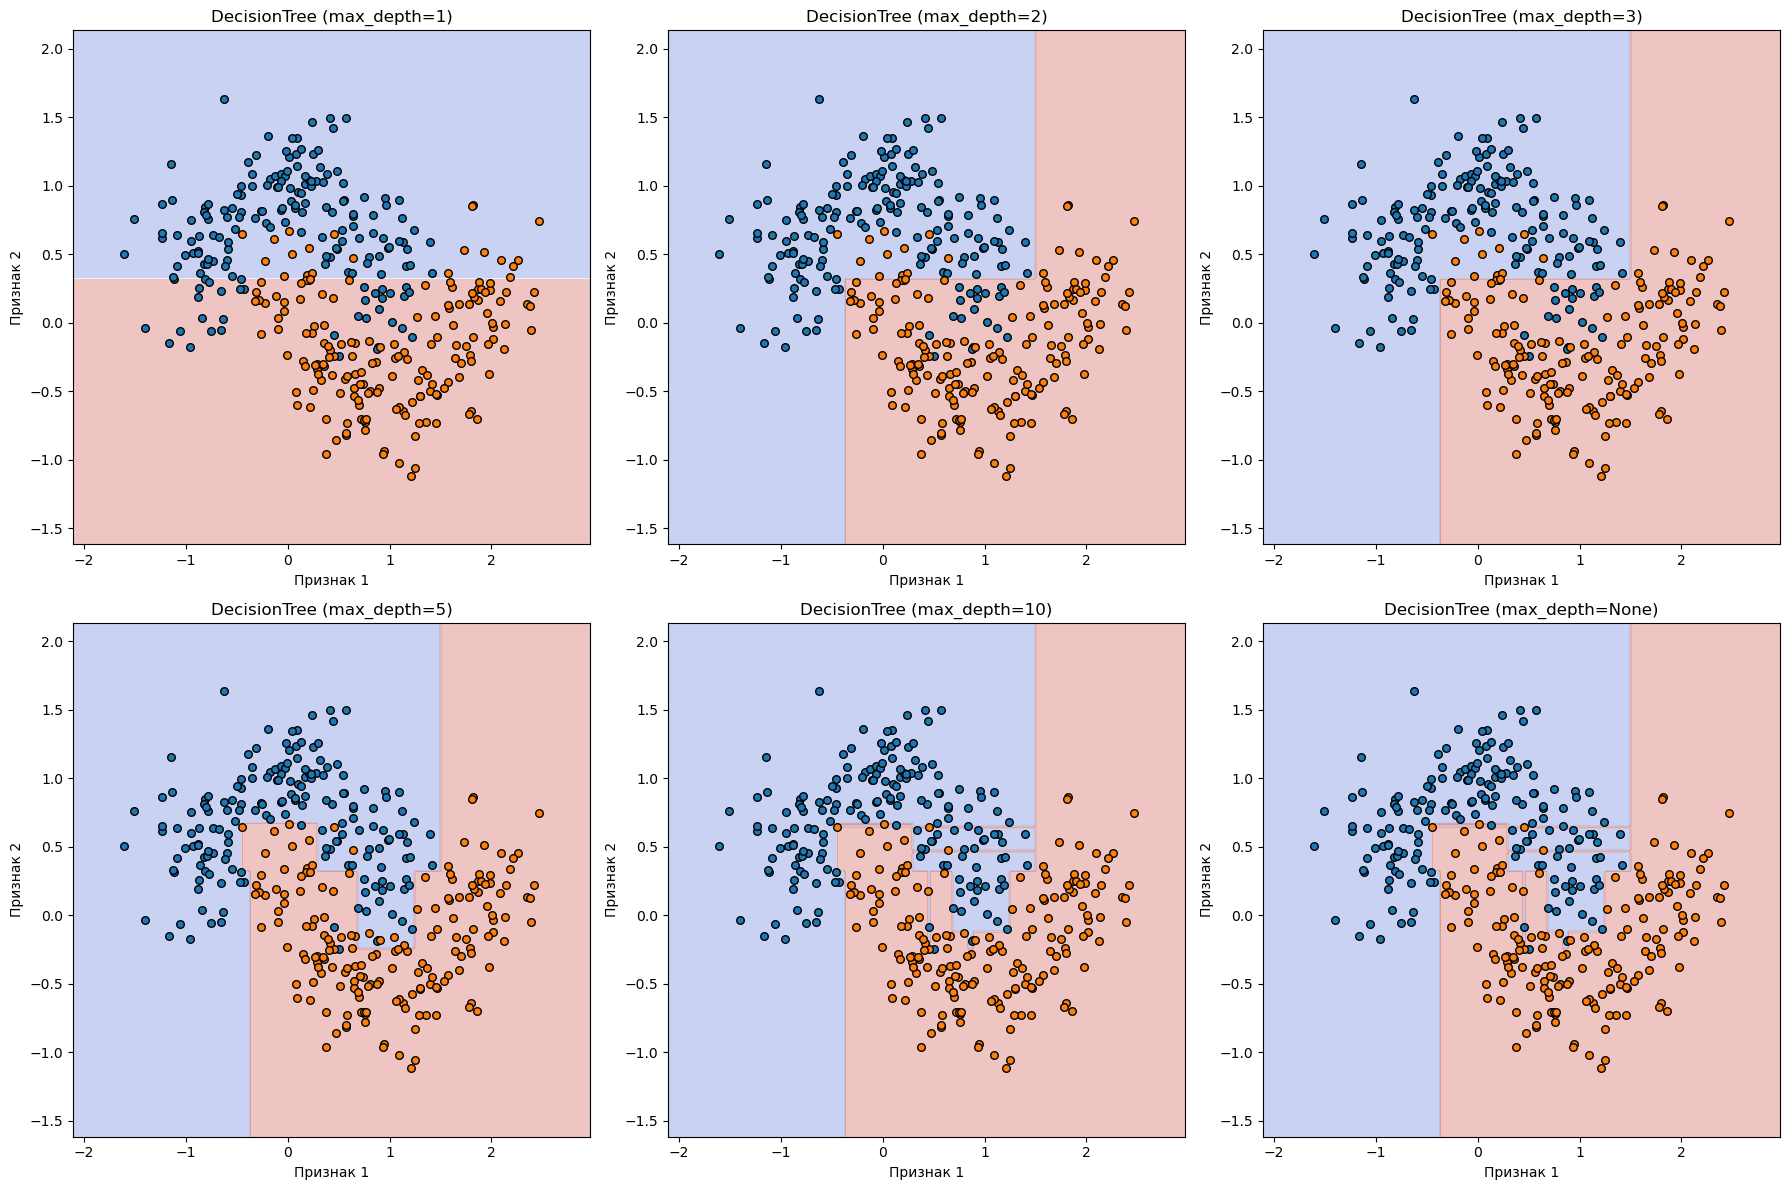

In [50]:
# границы решений для дерева с разными глубинами
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, d in zip(axes.ravel(), depths):
    tree = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    tree.fit(X_train, y_train)
    title = f'DecisionTree (max_depth={d})' if d is not None else 'DecisionTree (max_depth=None)'
    plot_decision_boundary(tree, X_train, y_train, title, ax)
plt.tight_layout()
plt.show()

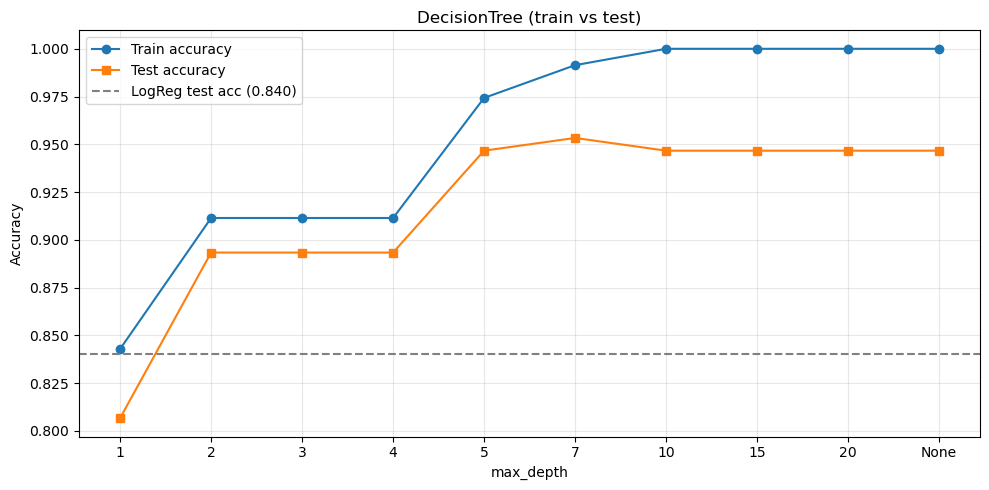

In [52]:
# кривая обучения: train vs test accuracy от глубины
depths_plot = [1, 2, 3, 4, 5, 7, 10, 15, 20, None]
train_accs, test_accs = [], []

for d in depths_plot:
    tree = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    tree.fit(X_train, y_train)
    train_accs.append(accuracy_score(y_train, tree.predict(X_train)))
    test_accs.append(accuracy_score(y_test, tree.predict(X_test)))

x_labels = [str(d) if d is not None else 'None' for d in depths_plot]
x_pos = range(len(depths_plot))

plt.figure(figsize=(10, 5))
plt.plot(x_pos, train_accs, 'o-', label='Train accuracy')
plt.plot(x_pos, test_accs, 's-', label='Test accuracy')
plt.axhline(acc_test_lr, color='gray', linestyle='--', label=f'LogReg test acc ({acc_test_lr:.3f})')
plt.xticks(x_pos, x_labels)
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('DecisionTree (train vs test)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [54]:
import pandas as pd

summary = pd.DataFrame({
    'Модель': ['LogisticRegression'] + [f'DecisionTree(depth={d})' for d in [1, 2, 3, 5, 10, None]],
    'Train acc': [acc_train_lr] + [r[1] for r in tree_results],
    'Test acc': [acc_test_lr] + [r[2] for r in tree_results],
})
summary['Разрыв (train-test)'] = summary['Train acc'] - summary['Test acc']
print(summary.to_string(index=False))

                  Модель  Train acc  Test acc  Разрыв (train-test)
      LogisticRegression   0.854286  0.840000             0.014286
   DecisionTree(depth=1)   0.842857  0.806667             0.036190
   DecisionTree(depth=2)   0.911429  0.893333             0.018095
   DecisionTree(depth=3)   0.911429  0.893333             0.018095
   DecisionTree(depth=5)   0.974286  0.946667             0.027619
  DecisionTree(depth=10)   1.000000  0.946667             0.053333
DecisionTree(depth=None)   1.000000  0.946667             0.053333


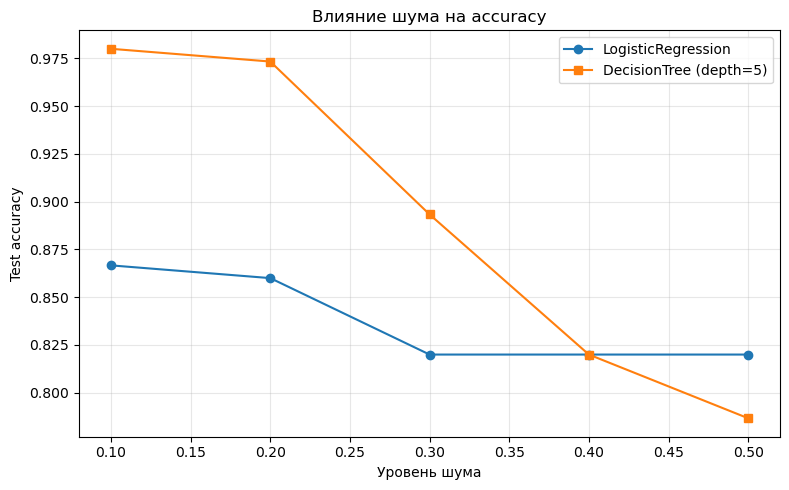

noise=0.1: LR=0.867, Tree=0.980
noise=0.2: LR=0.860, Tree=0.973
noise=0.3: LR=0.820, Tree=0.893
noise=0.4: LR=0.820, Tree=0.820
noise=0.5: LR=0.820, Tree=0.787


In [56]:
# ак шум влияет на линейную модель и дерево
noises = [0.1, 0.2, 0.3, 0.4, 0.5]
lr_accs, tree_accs = [], []

for noise in noises:
    Xn, yn = make_moons(n_samples=500, noise=noise, random_state=RANDOM_STATE)
    Xtr, Xte, ytr, yte = train_test_split(Xn, yn, test_size=0.3,
                                          random_state=RANDOM_STATE, stratify=yn)

    lr = LogisticRegression(random_state=RANDOM_STATE).fit(Xtr, ytr)
    tree = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE).fit(Xtr, ytr)

    lr_accs.append(accuracy_score(yte, lr.predict(Xte)))
    tree_accs.append(accuracy_score(yte, tree.predict(Xte)))

plt.figure(figsize=(8, 5))
plt.plot(noises, lr_accs, 'o-', label='LogisticRegression')
plt.plot(noises, tree_accs, 's-', label='DecisionTree (depth=5)')
plt.xlabel('Уровень шума')
plt.ylabel('Test accuracy')
plt.title('Влияние шума на accuracy')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for n, lr_a, tr_a in zip(noises, lr_accs, tree_accs):
    print(f"noise={n:.1f}: LR={lr_a:.3f}, Tree={tr_a:.3f}")

LogisticRegression + PolynomialFeatures(3) — test acc: 0.933


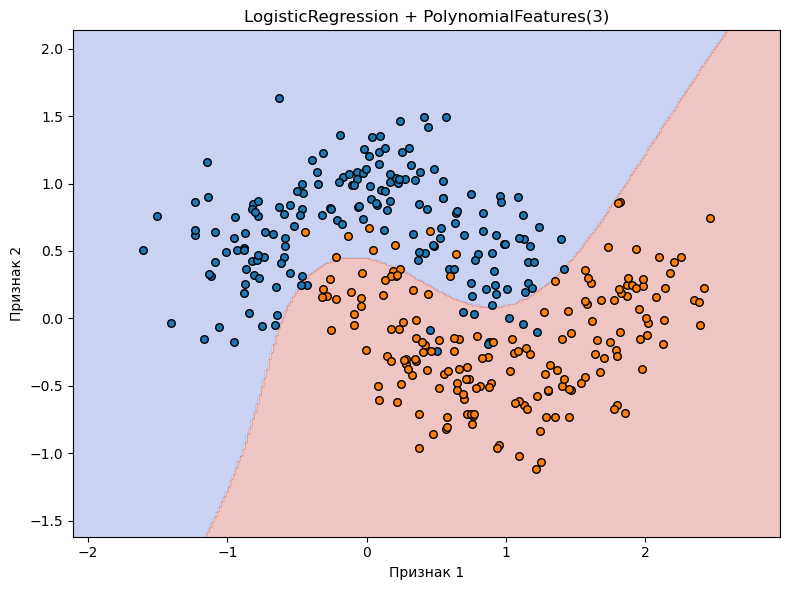

In [58]:
# если дать линейной модели нелинейные признаки
poly_lr = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
)
poly_lr.fit(X_train, y_train)
poly_acc = accuracy_score(y_test, poly_lr.predict(X_test))
print(f"LogisticRegression + PolynomialFeatures(3) — test acc: {poly_acc:.3f}")

fig, ax = plt.subplots(figsize=(8, 6))
plot_decision_boundary(poly_lr, X_train, y_train,
                       'LogisticRegression + PolynomialFeatures(3)', ax)
plt.tight_layout()
plt.show()

## Вывод

- **LogisticRegression** (линейная модель): test accuracy = 0.84. Прямая граница не разделяет «полумесяцы».
- **DecisionTree**: оптимум при `max_depth=5` - test accuracy = 0.95. При `max_depth>=10` - переобучение (train=1.0, test=0.95).
- **Шум**: при noise=0.5 дерево проигрывает линейной модели (0.787 vs 0.820) - деревья чувствительны к шуму.
- **Полиномиальные признаки** для LogisticRegression поднимают accuracy до 0.93 - линейная модель «учится» нелинейной границе.

Подробные выводы - в `README.md`.